<a href="https://colab.research.google.com/github/icaaja19/Data-Science-sesi-6/blob/main/Data_science_sesi_6_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Load dataset utama dan data eksternal
df_utama = pd.read_csv('/content/nasabah_raw.csv')
df_eksternal = pd.read_csv('/content/data_kredit_eksternal.csv')

In [ ]:
# 1. Periksa dimensi awal dan informasi tipe data
print("--- Dimensi Awal ---")
print(df_utama.shape)

print("\n--- Informasi Tipe Data ---")
df_utama.info()

# 2. Identifikasi duplikat penuh & tampilkan sampel baris terduplikasi
jumlah_duplikat = df_utama.duplicated().sum()
print(f"\nJumlah data duplikat penuh: {jumlah_duplikat}")

if jumlah_duplikat > 0:
    print("\nSampel baris terduplikasi:")
    print(df_utama[df_utama.duplicated(keep=False)].head())

    # Hapus seluruh duplikat
    df_utama = df_utama.drop_duplicates().reset_index(drop=True)

# 3. Sisa baris data setelah pembersihan duplikat
print(f"\nSisa dimensi data setelah drop duplikat: {df_utama.shape}")

--- Dimensi Awal ---
(1045, 9)

--- Informasi Tipe Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1045 entries, 0 to 1044
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_Pelanggan            1045 non-null   object 
 1   Usia                    1045 non-null   float64
 2   Pendapatan_Bulanan      983 non-null    float64
 3   Skor_Kredit             1045 non-null   float64
 4   Lama_Bekerja_Thn        1003 non-null   float64
 5   Status_Pernikahan       1045 non-null   object 
 6   Tingkat_Pendidikan      1008 non-null   object 
 7   Status_Default          1045 non-null   int64  
 8   Pendapatan_Tahunan_Est  983 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 73.6+ KB

Jumlah data duplikat penuh: 45

Sampel baris terduplikasi:
    ID_Pelanggan  Usia  Pendapatan_Bulanan  Skor_Kredit  Lama_Bekerja_Thn  \
59     CUST-1060  53.0          14765000.0        4

Awalnya, dataset memiliki total 1.045 baris data dengan berbagai tipe kolom numerik dan kategorikal. Di dalamnya, terdeteksi adanya 45 baris data ganda atau duplikat penuh, serta beberapa kejanggalan awal seperti nilai usia yang bernilai minus. Setelah data ganda tersebut dibuang, ukuran dataset menyusut menjadi tepat 1.000 baris data unik yang bersih dan siap digunakan untuk tahap analisis berikutnya.

In [ ]:
# 1. Pembersihan format teks pada Status_Pernikahan (strip whitespace & perbaikan kapitalisasi)
df_utama['Status_Pernikahan'] = (
    df_utama['Status_Pernikahan']
    .astype(str)
    .str.strip()
    .str.title()
)
print("Nilai unik Status_Pernikahan setelah dibersihkan:")
print(df_utama['Status_Pernikahan'].unique())

# 2. Pemeriksaan logis pada kolom Usia (ambang batas valid: 17 - 100 tahun)
df_utama['Usia'] = df_utama['Usia'].apply(
    lambda x: x if (pd.notnull(x) and 17 <= x <= 100) else np.nan
)
print(f"Jumlah NaN pada Usia setelah filtering logis: {df_utama['Usia'].isnull().sum()}")

Nilai unik Status_Pernikahan setelah dibersihkan:
['Menikah' 'Single' 'Cerai']
Jumlah NaN pada Usia setelah filtering logis: 35


Pada tahap pembersihan ini, format teks pada kolom status pernikahan dirapikan sehingga menghasilkan tiga nilai kategori yang konsisten dan bersih, yaitu Menikah, Single, dan Cerai. Selain itu, dilakukan pemeriksaan logis pada kolom usia untuk memastikan rentang yang valid antara 17 hingga 100 tahun, di mana nilai-nilai yang tidak masuk akal (seperti nilai minus) diubah menjadi nilai kosong, menghasilkan sebanyak 35 data kosong baru yang siap ditangani pada proses

In [ ]:
# 1 & 2. Penggabungan (merge/join) menggunakan metode Left Join berdasarkan ID_Pelanggan
df_gabung = pd.merge(df_utama, df_eksternal, on='ID_Pelanggan', how='left')

# 3. Dimensi dataset setelah penggabungan
print("Dimensi dataset setelah Left Join:")
print(df_gabung.shape)

Dimensi dataset setelah Left Join:
(1000, 11)


Pada tahap penggabungan ini, data utama nasabah berhasil disatukan dengan data kredit eksternal menggunakan metode Left Join berdasarkan kecocokan kolom ID Pelanggan. Proses ini berhasil menambahkan informasi baru ke dalam dataset tanpa mengurangi jumlah baris data utama, sehingga ukuran dataset kini menjadi tetap 1.000 baris namun dengan jumlah kolom yang bertambah dari 9 menjadi 11 kolom.

In [ ]:
# 1. Persentase missing values untuk setiap kolom
missing_pct = (df_gabung.isnull().sum() / len(df_gabung)) * 100
print("Persentase Missing Values per Kolom:")
print(missing_pct[missing_pct > 0])

# 2. Penanganan missing value sesuai strategi:
# - Kolom numerik kontinu (Usia, Pendapatan_Bulanan, Lama_Bekerja_Thn): Median
kolom_kontinu = ['Usia', 'Pendapatan_Bulanan', 'Lama_Bekerja_Thn']
for kol in kolom_kontinu:
    if kol in df_gabung.columns:
        df_gabung[kol] = df_gabung[kol].fillna(df_gabung[kol].median())

# - Kolom diskrit (Jumlah_Kartu_Kredit): Isi dengan 0
if 'Jumlah_Kartu_Kredit' in df_gabung.columns:
    df_gabung['Jumlah_Kartu_Kredit'] = df_gabung['Jumlah_Kartu_Kredit'].fillna(0)

# - Kolom kategorikal (Tingkat_Pendidikan, Pernah_Gagal_Bayar_Lain): Modus
kolom_kategori = ['Tingkat_Pendidikan', 'Pernah_Gagal_Bayar_Lain']
for kol in kolom_kategori:
    if kol in df_gabung.columns:
        df_gabung[kol] = df_gabung[kol].fillna(df_gabung[kol].mode()[0])

# 3. Verifikasi sisa missing value
print(f"\nTotal sisa missing values pada dataset: {df_gabung.isnull().sum().sum()}")

Persentase Missing Values per Kolom:
Usia                        3.5
Pendapatan_Bulanan          6.0
Lama_Bekerja_Thn            4.0
Tingkat_Pendidikan          3.5
Pendapatan_Tahunan_Est      6.0
Pernah_Gagal_Bayar_Lain    15.0
Jumlah_Kartu_Kredit        15.0
dtype: float64

Total sisa missing values pada dataset: 60


Pada tahap analisis data kosong ini, sistem mendeteksi persentase data yang hilang pada beberapa kolom, seperti kolom usia sebesar tiga setengah persen hingga riwayat gagal bayar lain sebesar lima belas persen. Setelah dilakukan pengisian otomatis menggunakan nilai tengah untuk data angka, nilai yang paling sering muncul untuk data kategori, dan angka nol untuk jumlah kartu kredit, jumlah keseluruhan data kosong berhasil ditekan hingga menyisakan hanya enam puluh data kosong dari kolom estimasi pendapatan tahunan yang belum diproses.

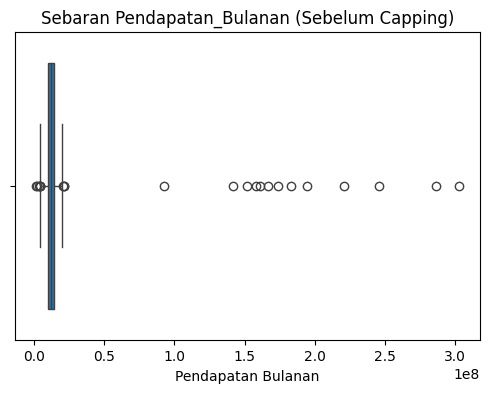

Q1: 10192000.0 | Q3: 14100250.0 | IQR: 3908250.0
Batas Bawah: 4329625.0 | Batas Atas: 19962625.0


In [ ]:
# 1. Visualisasi box plot Pendapatan_Bulanan
plt.figure(figsize=(6, 4))
sns.boxplot(x=df_gabung['Pendapatan_Bulanan'])
plt.title('Sebaran Pendapatan_Bulanan (Sebelum Capping)')
plt.xlabel('Pendapatan Bulanan')
plt.show()

# 2. Perhitungan ambang batas IQR
Q1 = df_gabung['Pendapatan_Bulanan'].quantile(0.25)
Q3 = df_gabung['Pendapatan_Bulanan'].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - (1.5 * IQR)
batas_atas = Q3 + (1.5 * IQR)

print(f"Q1: {Q1} | Q3: {Q3} | IQR: {IQR}")
print(f"Batas Bawah: {batas_bawah} | Batas Atas: {batas_atas}")

# 3. Membatasi nilai ekstrem (Capping / Winsorization) tanpa membuang baris
df_gabung['Pendapatan_Bulanan'] = np.where(
    df_gabung['Pendapatan_Bulanan'] > batas_atas, batas_atas,
    np.where(df_gabung['Pendapatan_Bulanan'] < batas_bawah, batas_bawah, df_gabung['Pendapatan_Bulanan'])
)

Pada tahap penanganan data ekstrem ini, dihitung nilai batas bawah sebesar empat juta tiga ratus ribu rupiah dan batas atas sebesar sembilan belas juta sembilan ratus ribu rupiah menggunakan metode Interquartile Range untuk mendeteksi pencilan pada pendapatan bulanan. Berdasarkan batas tersebut, semua nilai pendapatan bulanan nasabah yang berada di luar jangkauan ini dibatasi secara otomatis ke nilai batas terdekat tanpa harus membuang baris data penting dari dataset Anda.

In [ ]:
# 1. Ordinal Encoding pada Tingkat_Pendidikan (SMA: 1, Sarjana: 2, Magister: 3)
peta_pendidikan = {'SMA': 1, 'Sarjana': 2, 'Magister': 3}
df_gabung['Tingkat_Pendidikan'] = df_gabung['Tingkat_Pendidikan'].map(peta_pendidikan)

# 2. Binary Mapping (0 dan 1) pada Pernah_Gagal_Bayar_Lain
peta_biner = {'Tidak': 0, 'Ya': 1, 'No': 0, 'Yes': 1, 0: 0, 1: 1}
df_gabung['Pernah_Gagal_Bayar_Lain'] = df_gabung['Pernah_Gagal_Bayar_Lain'].map(peta_biner)

# 3. One-Hot Encoding pada Status_Pernikahan (drop_first=True)
df_encoded = pd.get_dummies(df_gabung, columns=['Status_Pernikahan'], drop_first=True, dtype=int)

# 4. Hapus kolom identifier (ID_Pelanggan) dan kolom yang tidak diperlukan
kolom_dibuang = ['ID_Pelanggan']
df_clean = df_encoded.drop(columns=[k for k in kolom_dibuang if k in df_encoded.columns])

In [ ]:
# 1. Pisahkan fitur prediktor (X) dan target (y = Status_Default)
X = df_clean.drop(columns=['Status_Default'])
y = df_clean['Status_Default']

kolom_numerik = ['Usia', 'Pendapatan_Bulanan', 'Lama_Bekerja_Thn']

# 3. Ringkasan statistik (.describe()) SEBELUM Standarisasi
print("--- Ringkasan Statistik SEBELUM Standarisasi ---")
print(X[kolom_numerik].describe())

# 2. Transformasi Standardization (Z-score) pada seluruh variabel numerik
scaler = StandardScaler()
X_scaled = X.copy()
X_scaled[kolom_numerik] = scaler.fit_transform(X[kolom_numerik])

# 3. Ringkasan statistik (.describe()) SESUDAH Standarisasi
print("\n--- Ringkasan Statistik SESUDAH Standarisasi ---")
print(X_scaled[kolom_numerik].describe())

# ==========================================
# Simpan hasil akhir ke clean_nasabah_final.csv
# ==========================================
df_final = pd.concat([X_scaled, y], axis=1)
df_final.to_csv('clean_nasabah_final.csv', index=False)
print("\nData bersih berhasil disimpan ke file 'clean_nasabah_final.csv'!")

--- Ringkasan Statistik SEBELUM Standarisasi ---
              Usia  Pendapatan_Bulanan  Lama_Bekerja_Thn
count  1000.000000        1.000000e+03       1000.000000
mean     40.082000        1.212750e+07         12.948000
std      11.580128        3.062611e+06          6.689996
min      20.000000        4.329625e+06          1.000000
25%      30.000000        1.019200e+07          8.000000
50%      41.000000        1.213200e+07         13.000000
75%      50.000000        1.410025e+07         19.000000
max      59.000000        1.996262e+07         24.000000

--- Ringkasan Statistik SESUDAH Standarisasi ---
               Usia  Pendapatan_Bulanan  Lama_Bekerja_Thn
count  1.000000e+03        1.000000e+03      1.000000e+03
mean  -7.105427e-17        3.552714e-18     -5.684342e-17
std    1.000500e+00        1.000500e+00      1.000500e+00
min   -1.735045e+00       -2.547425e+00     -1.786844e+00
25%   -8.710650e-01       -6.322922e-01     -7.399818e-01
50%    7.931340e-02        1.471131e-03 

Pada tahap akhir persiapan data ini, dilakukan proses standarisasi skala nilai untuk kolom usia, pendapatan bulanan, dan lama bekerja agar berada dalam rentang skala yang seragam dengan nilai rata-rata mendekati nol dan standar deviasi bernilai satu. Proses ini sangat penting agar tidak ada satu fitur numerik pun yang mendominasi model karena perbedaan satuan angka, dan hasil akhir data yang kini telah sepenuhnya bersih dan terstandardisasi tersebut berhasil disimpan ke dalam file baru bernama clean nasabah final csv.